# M67 Analysis

In [16]:
import os
os.chdir("/Users/nataliaazanongarcia/Downloads")
print(os.getcwd())

/Users/nataliaazanongarcia/Downloads


In [17]:
print(os.path.exists("M67 G-band image.fits"))
print(os.path.exists("M67 R-band image.fits"))

True
True


In [18]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [19]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)
        

Text(0.5, 1.0, 'M67 G-band image')

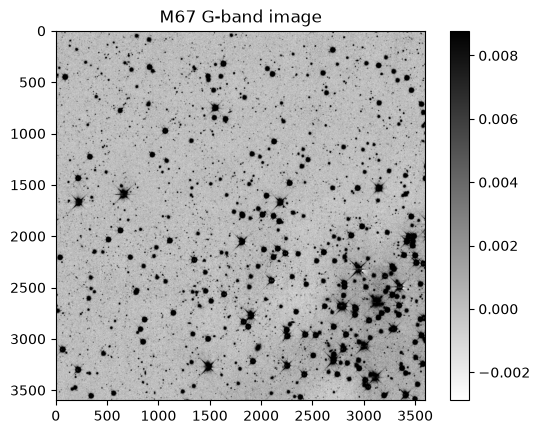

In [20]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M67 G-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M67 G-band image")

**Why:** We plotted the G-band image to see the stars in M67 and check the quality of the image before measuring their brightness.

**What we found:** The image contains many sources with different brightness levels. Some stars are close together, which may make their measurements more difficult.

Text(0.5, 1.0, 'M67 R-band image')

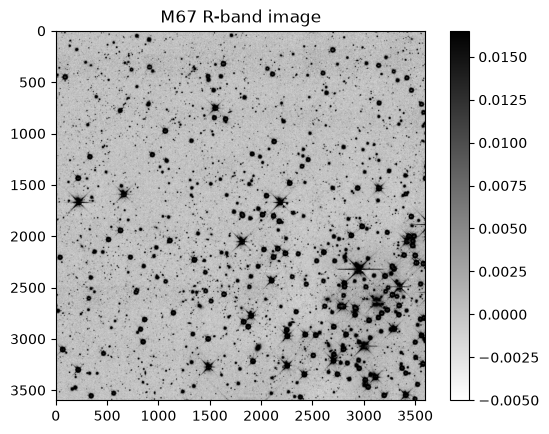

In [21]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M67 R-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M67 R-band image")

**Why:** We plotted the R-band image to compare it with the G-band image and see the stars in a different filter.

**What we found:** Many sources are visible in both images, but their brightness can be different between the two filters. We need both images to calculate stellar colors.

In [22]:
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess, pixels
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [23]:
# Calculate FWHM for M67 G-band

M67Gstars = [(1652.23, 2890.77),(1332.9, 2945.23),(3234.83, 1962), (3413.16, 453.704),(1800.83, 3299.43)]

M67G_fwhm = calc_fwhm('M67 G-band image.fits', M67Gstars)

print("G-band FWHM:", M67G_fwhm)
print("Mean G-band FWHM:", np.mean(M67G_fwhm))
print("Median G-band FWHM:", np.median(M67G_fwhm))

The FWHM of the stars in M67 G-band image.fits in pixels are [4.75709268 5.77459119 5.27015913 4.94039666 4.77424869]
G-band FWHM: [4.75709268 5.77459119 5.27015913 4.94039666 4.77424869]
Mean G-band FWHM: 5.103297669904445
Median G-band FWHM: 4.9403966604812055


In [24]:
#load M67 images again

from astropy.io import fits

M67data_G, M67header_G = fits.getdata("M67 G-band image.fits", header=True)

M67data_R, M67header_R = fits.getdata("M67 R-band image.fits", header=True)

print("M67 images loaded successfully!")

M67 images loaded successfully!


In [25]:
#detect stars in M67 G-band again

from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats

#estimate background in G
M67mean_G, M67median_G, M67std_G = sigma_clipped_stats(M67data_G, sigma=3.0)

print("G-band background median:", M67median_G)
print("G-band background std:", M67std_G)

# Detect stars
daofind = DAOStarFinder(fwhm=5.10, threshold=80.0 * M67std_G)
M67sources_G = daofind(M67data_G - M67median_G)

print("Detected G-band sources:", len(M67sources_G))
print(M67sources_G[:5])

G-band background median: 0.00029238948
G-band background std: 0.0026621935
Detected G-band sources: 526
 id     x_centroid     ...         mag            daofind_mag    
--- ------------------ ... ------------------- ------------------
  1 1162.1007381068498 ...  -3.272835857018726 -2.068512063002561
  2 3121.4956344932834 ... -3.0793167188828603  -1.39723207948631
  3  1755.934865186145 ... -2.1123509180886115 -0.804156963703641
  4 1711.6986804368362 ...  -5.811178120867072 -4.632967471523224
  5   789.833494839115 ...  -6.565226920368151 -5.484168037776918


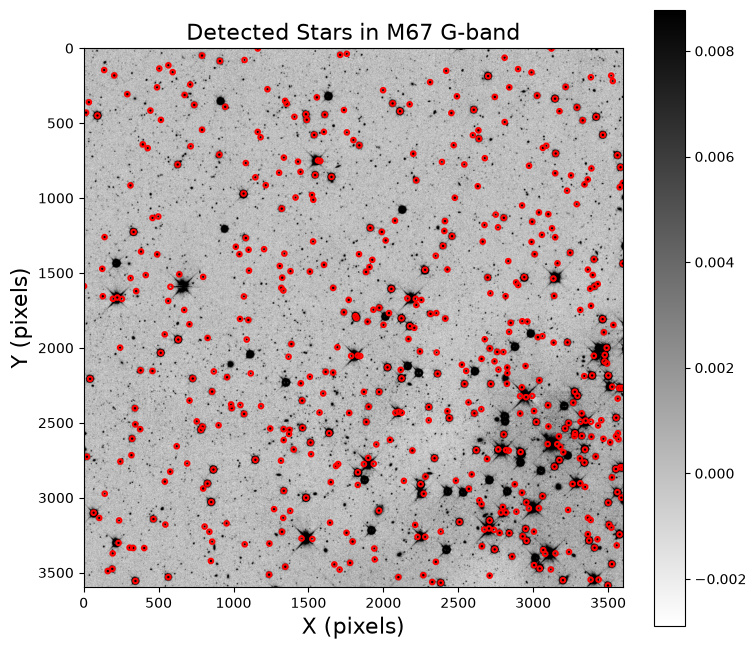

In [26]:
# Plot detected stars in M67 G-band

plt.figure(figsize=(8, 8))

imdisplay(M67data_G)

positions_G = np.transpose((M67sources_G['x_centroid'], M67sources_G['y_centroid']))

apertures_G = CircularAperture(positions_G, r=15)
apertures_G.plot(color='red', lw=1.5)

plt.title('Detected Stars in M67 G-band', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

plt.show()

**Why:** We plotted the detected stars on the G-band image to check if the program was finding real sources.

**What we found:** We detected 522 sources in the G-band image. The circles show their positions and help us visually check the detection process.

Text(0.5, 1.0, 'M67 G-band')

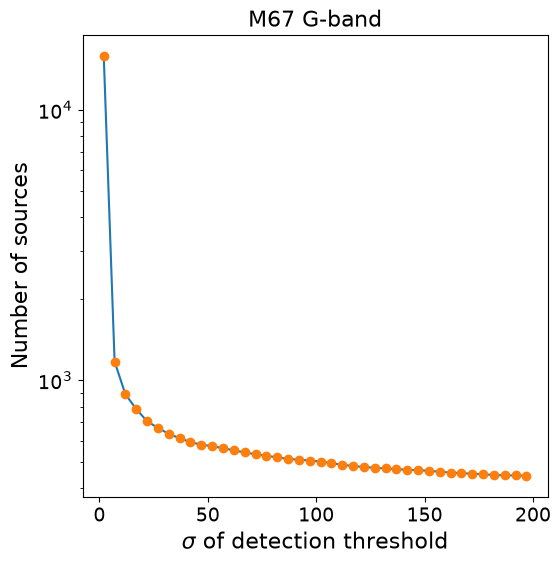

In [27]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,200.,5)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_G = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=4.94, threshold=thresh*M67std_G)
    M67sources_Gtmp = daofind(M67data_G - M67median_G)
    nsources_G[ithresh] = len(M67sources_Gtmp) if M67sources_Gtmp is not None else 0

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_G)
ax.plot(thresharr,nsources_G, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=16)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M67 G-band', fontsize=16)

**Why:** We tested different detection thresholds to understand how they affect the number of stars detected.

**What we found:** Lower thresholds detect more sources, but some may be noise. Higher thresholds detect fewer sources because only brighter signals are selected. This helped us understand the effect of the detection threshold.

In [28]:
#calculate FWHM for M67 R-band

M67Rstars = [(2172.5, 1942.17),(2989.81, 1162.01),(3391.04, 1711.84),(1236.31, 3301.88),(1994.18, 1236.31)]
M67R_fwhm = calc_fwhm('M67 R-band image.fits', M67Rstars)

print("R-band FWHM:", M67R_fwhm)
print("Mean R-band FWHM:", np.mean(M67R_fwhm))
print("Median R-band FWHM:", np.median(M67R_fwhm))

The FWHM of the stars in M67 R-band image.fits in pixels are [4.9067584  4.4778736  4.14880319 4.34893221 5.0652364 ]
R-band FWHM: [4.9067584  4.4778736  4.14880319 4.34893221 5.0652364 ]
Mean R-band FWHM: 4.589520761495637
Median R-band FWHM: 4.47787360333826


In [30]:
#detect stars in M67 R-band again

from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats

#estimate background in R
M67mean_R, M67median_R, M67std_R = sigma_clipped_stats(M67data_R, sigma=3.0)

print("R-band background median:", M67median_R)
print("R-band background std:", M67std_R)

# Detect stars
daofind = DAOStarFinder(fwhm=4.59, threshold=40.0 * M67std_R)

M67sources_R = daofind(M67data_R - M67median_R)

print("Detected R-band sources:", len(M67sources_R))
print(M67sources_R[:5])

R-band background median: 0.0005223558
R-band background std: 0.004611779
Detected R-band sources: 730
 id     x_centroid     ...         mag             daofind_mag     
--- ------------------ ... ------------------- --------------------
  1 3121.6562882652843 ... -3.5264579524516035  -2.3424682701646766
  2 1162.0138542331488 ... -3.5003041653061677   -2.327815705743639
  3 3388.9189466516386 ...  -1.814728253458784  -0.8840362887858277
  4 2702.1173740754325 ...  -2.690638127108786  -1.7472660723023703
  5 1545.8012471103445 ... -1.3710396450350517 -0.43533933913159084


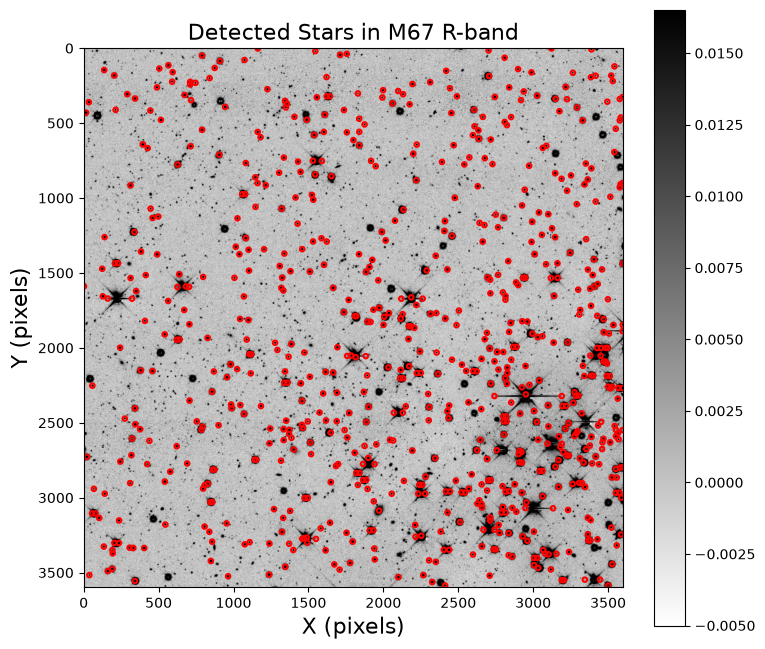

In [31]:
#Plot detected stars in M67 R-band

plt.figure(figsize=(8, 8))

imdisplay(M67data_R)

positions_R = np.transpose((M67sources_R['x_centroid'],M67sources_R['y_centroid']))

apertures_R = CircularAperture(positions_R, r=15)
apertures_R.plot(color='red', lw=1.5)

plt.title('Detected Stars in M67 R-band', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

plt.show()

**Why:** We plotted the detected sources in the R-band image to check their positions and compare them with the G-band detections.

**What we found:** We detected 777 sources in the R-band image. This is more than in the G-band image, showing that the detection results depend on the filter and the detection settings.

Text(0.5, 1.0, 'M67 R-band')

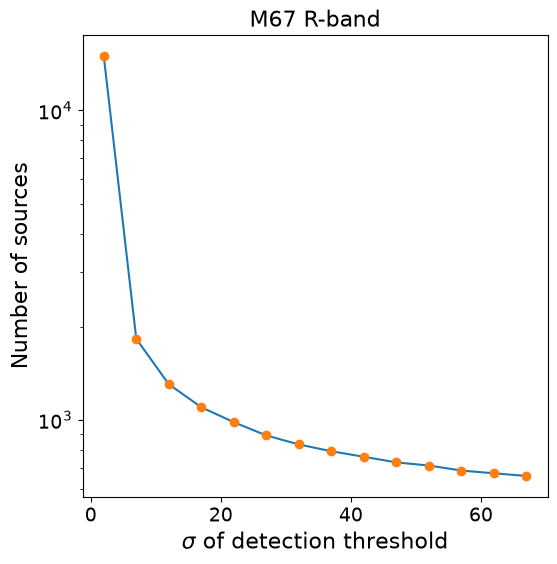

In [32]:
#This makes a plot of the number of sources for different detection thresholds for the R-band
#set up an array of thresholds
thresharr = np.arange(2.,70.,5)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_R = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=5.0, threshold=thresh*M67std_R)
    M67sources_Rtmp = daofind(M67data_R - M67median_R)
    nsources_R[ithresh] = len(M67sources_Rtmp) if M67sources_Rtmp is not None else 0

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_R)
ax.plot(thresharr,nsources_R, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=16)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M67 R-band', fontsize=16)

**Why:** We tested different thresholds in the R-band image to see how the number of detected sources changes.

**What we found:** The number of detected sources decreases as the threshold increases. This shows the importance of choosing a threshold that detects stars without including too much noise.

In [33]:
# Calculate background statistics for M67 G-band

M67mean_G, M67median_G,M67std_G =sigma_clipped_stats(M67data_G, sigma=3.0)

print("Mean:",M67mean_G)
print("Median:", M67median_G)
print("Standard deviation:",M67std_G)

Mean: 0.0003671612
Median: 0.00029238948
Standard deviation: 0.0026621935


In [34]:
# Find stars in M67 G-band

M67daofind_G =DAOStarFinder(fwhm=4.94,threshold=80*M67std_G)

M67sources_G =M67daofind_G(M67data_G-M67median_G)

print("Number of detected stars:",len(M67sources_G))
print(M67sources_G[:10])

Number of detected stars: 522
 id     x_centroid     ...         mag             daofind_mag    
--- ------------------ ... ------------------- -------------------
  1  3121.557149199795 ... -2.7338893562819573 -1.1810315682464947
  2 1162.1013674671267 ...  -3.153711034734563 -1.7865960770812108
  3 1755.9345214111863 ... -1.9667220685901716 -0.5943619368224515
  4 1711.6979833832504 ...  -5.676413355569956 -4.4381889832641495
  5  789.8331170326287 ...  -6.437878091925569  -5.305261256032166
  6 2809.3273207963766 ...  -3.034552998517117  -1.661386302496107
  7 1073.4970877546752 ... -1.4927872186090818 -0.2998322297838601
  8  909.3192847868979 ...   -6.59949143890498  -5.007101160136946
  9  565.1775897677409 ...  -3.442610841991086 -2.3741553402409217
 10 504.66529724203906 ...  -2.480639905584435 -1.1858469505140492


In [35]:
# Calculate background statistics for M67 R-band

M67mean_R, M67median_R, M67std_R = sigma_clipped_stats(M67data_R, sigma=3.0)

print("Mean:", M67mean_R)
print("Median:", M67median_R)
print("Standard deviation:", M67std_R)

Mean: 0.0006474414
Median: 0.0005223558
Standard deviation: 0.004611779


In [36]:
# Find stars in M67 R-band

M67daofind_R = DAOStarFinder(fwhm=5.0,threshold=40*M67std_R)

M67sources_R = M67daofind_R(M67data_R - M67median_R)

print("Number of detected stars:", len(M67sources_R))
print(M67sources_R[:10])

Number of detected stars: 777
 id     x_centroid     ...         mag             daofind_mag     
--- ------------------ ... ------------------- --------------------
  1 1162.0033096750321 ... -3.6726479536534233  -2.7931629484418257
  2  3121.544537095122 ... -3.9464848082034774  -2.6606616316806777
  3  3388.910318413897 ... -1.9949858825558118  -1.2055698059972328
  4 2702.1084678892107 ... -2.8829434119996944  -2.0513942139891927
  5 1545.8085471129243 ...  -1.547065020107494  -0.7688360589802952
  6 1755.8957370331625 ...  -3.058997205173457  -2.2406413180624503
  7 1711.7062074493444 ...  -6.751178984785807   -5.829799000095224
  8  789.7974052766688 ...  -6.922190192183292   -5.806432719754998
  9 3131.3928059708232 ... -1.4913562104659221 -0.23303761621799607
 10 2809.3738280292614 ...  -4.701908394135169   -3.829614957204143


In [37]:
from astropy.coordinates import SkyCoord
from astropy import units as u

# Convert pixel coordinates to RA and DEC
M67wcs_G =WCS(M67header_G)
M67wcs_R =WCS(M67header_R)

M67ra_G, M67dec_G = M67wcs_G.all_pix2world( M67sources_G['x_centroid'], M67sources_G['y_centroid'], 0)

M67ra_R, M67dec_R= M67wcs_R.all_pix2world( M67sources_R['x_centroid'], M67sources_R['y_centroid'], 0)

print("G coordinates:", len(M67ra_G))
print("R coordinates:", len(M67ra_R))

#this creates a SkyCoord object containing the G and R catalogs
M67G_catalog = SkyCoord(ra=M67ra_G*u.degree, dec=M67dec_G*u.degree)
M67R_catalog = SkyCoord(ra=M67ra_R*u.degree, dec=M67dec_R*u.degree)

#this matches the two catalogs and outputs an array of indices, idx that when passed to v_catalog
#gives the ids of the match sources in the b_catalog.
idx, d2d, d3d = M67G_catalog.match_to_catalog_sky(M67R_catalog)

# we are going to keep matches that have offsets less than 2 arcseconds
matchflag = d2d < 0.4/3600*u.deg

bmag = M67sources_G['mag'][matchflag]
vmag = M67sources_R['mag'][idx[matchflag]]

print("Matched stars:", sum(matchflag))

G coordinates: 522
R coordinates: 777
Matched stars: 368


In [38]:
# Converting instrumental magnitudes to calibrated magnitudes

M67calibrated_Gmag=bmag +float(M67header_G['MAGZERO'])
M67calibrated_Rmag =vmag +float(M67header_R['MAGZERO'])

print(float(M67header_G['MAGZERO']))
print(float(M67header_R['MAGZERO']))

22.5
22.5


In [39]:
# Identify stars affected by clipping in R-band

M67peak_R = np.asarray(M67sources_R['peak'][idx[matchflag]])

# Keep stars below the suspected clipping level
valid_R = M67peak_R < 9.5

print("Total matched stars:", len(valid_R))
print("Stars below clipping threshold:", np.sum(valid_R))
print("Stars excluded:", np.sum(~valid_R))

Total matched stars: 368
Stars below clipping threshold: 211
Stars excluded: 157


In [40]:
# Check possible clipping in M67 R-band

print("Maximum R pixel value:", np.nanmax(M67data_R))
print("Maximum G pixel value:", np.nanmax(M67data_G))

print("R pixels above 9.9:", np.sum(M67data_R > 9.9))
print("R pixels above 10:", np.sum(M67data_R > 10))

print("Maximum detected R peak:", np.max(M67sources_R['peak']))
print("R sources with peak above 9.9:",
      np.sum(M67sources_R['peak'] > 9.9))

Maximum R pixel value: 79.13249
Maximum G pixel value: 137.43806
R pixels above 9.9: 41268
R pixels above 10: 22341
Maximum detected R peak: 79.13197
R sources with peak above 9.9: 306


In [45]:
#Inspect local pixel values around unusually blue stars

for i in range(min(5, len(M67blue_R))):
    x = int(round(M67blue_R['x_centroid'][i]))
    y = int(round(M67blue_R['y_centroid'][i]))

    cutout = M67data_R[y-5:y+6, x-5:x+6]

    print("Star", i+1)
    print("Position:", x, y)
    print("Central pixel:", M67data_R[y, x])
    print("Maximum in 11x11 region:", np.nanmax(cutout))
    print()

Star 1
Position: 2062 369
Central pixel: 10.0
Maximum in 11x11 region: 10.000045

Star 2
Position: 3293 396
Central pixel: 10.000045
Maximum in 11x11 region: 10.000045

Star 3
Position: 3583 795
Central pixel: 10.000033
Maximum in 11x11 region: 18.86699

Star 4
Position: 2398 1320
Central pixel: 10.000015
Maximum in 11x11 region: 10.000045

Star 5
Position: 3598 1438
Central pixel: 9.999959
Maximum in 11x11 region: 10.00005



In [46]:
#Identify sources with suspicious R-band peak values

M67peak_R= np.asarray(M67sources_R['peak'][idx[matchflag]])

suspect_R =np.abs(M67peak_R - 10.0) < 0.01

M67color =np.asarray(M67calibrated_Gmag - M67calibrated_Rmag)
blue_flag = M67color < -0.5

print("Total matched stars:", len(M67peak_R))
print("Sources with R peak near 10:", np.sum(suspect_R))
print("Blue sources:", np.sum(blue_flag))
print("Blue sources with R peak near 10:",
      np.sum(blue_flag & suspect_R))

Total matched stars: 368
Sources with R peak near 10: 22
Blue sources: 20
Blue sources with R peak near 10: 20


In [47]:
# Keep all stars except the suspicious R-band sources
clean_flag = ~suspect_R

print("Total matched stars:", len(clean_flag))
print("Stars kept:", np.sum(clean_flag))
print("Stars removed:", np.sum(suspect_R))

Total matched stars: 368
Stars kept: 346
Stars removed: 22


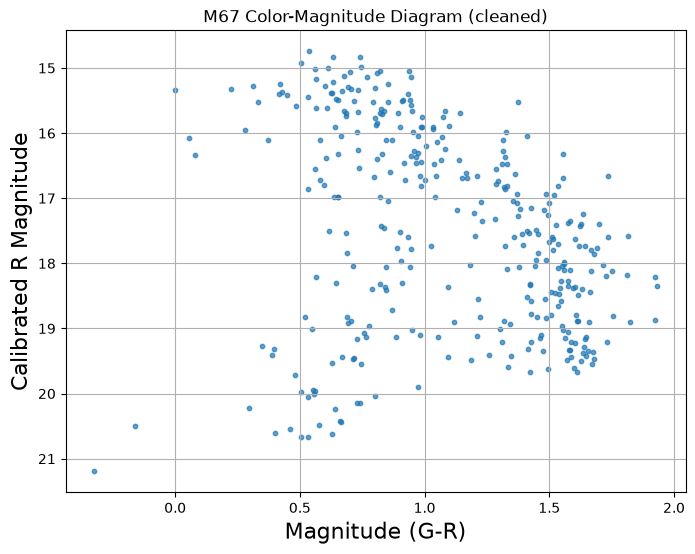

In [48]:
# Plot cleaned M67 Color-Magnitude Diagram

plt.figure(figsize=(8, 6))

plt.scatter(
    (M67calibrated_Gmag - M67calibrated_Rmag)[clean_flag],
    M67calibrated_Rmag[clean_flag],
    s=10,
    alpha=0.7
)

plt.gca().invert_yaxis()

plt.xlabel('Magnitude (G-R)', fontsize=16)
plt.ylabel('Calibrated R Magnitude', fontsize=16)
plt.title('M67 Color-Magnitude Diagram (cleaned)')

plt.grid(True)
plt.show()

**Why:** We removed sources with suspicious R-band peak values to see if they were affecting the shape of the CMD.

**What we found:** We removed 22 suspicious sources from the 368 matched detections, leaving 346 sources. The CMD shows a diagonal distribution of stars, although some points are still scattered.

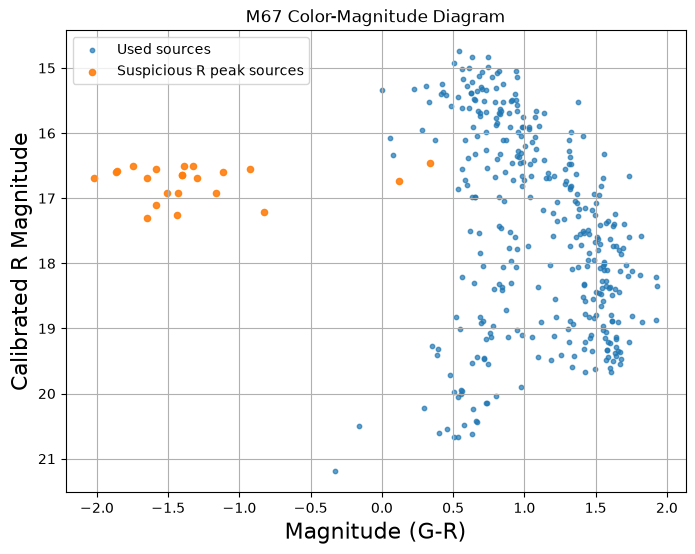

In [49]:
# Plot cleaned CMD and suspicious sources

plt.figure(figsize=(8, 6))

plt.scatter(
    (M67calibrated_Gmag - M67calibrated_Rmag)[clean_flag],
    M67calibrated_Rmag[clean_flag],
    s=10,
    alpha=0.7,
    label='Used sources'
)

plt.scatter(
    (M67calibrated_Gmag - M67calibrated_Rmag)[suspect_R],
    M67calibrated_Rmag[suspect_R],
    s=20,
    alpha=0.9,
    label='Suspicious R peak sources'
)

plt.gca().invert_yaxis()

plt.xlabel('Magnitude (G-R)', fontsize=16)
plt.ylabel('Calibrated R Magnitude', fontsize=16)
plt.title('M67 Color-Magnitude Diagram')
plt.legend()
plt.grid(True)
plt.show()

After matching the G and R catalogs, 368 sources were found in both filters.
22 sources had suspicious R-band peak values very close to 10, and 20 of those also showed unusually negative G−R colors.
These sources were treated as problematic photometric measurements and excluded from the cleaned CMD.
The final cleaned CMD for M67 therefore contains 346 sources.

### M67 – Preliminary Results

The G-band image contained 522 detected sources, while the R-band image contained 777. After matching the catalogs using a maximum separation of 0.4 arcseconds, 368 sources were matched.

We identified 22 sources with suspicious R-band peak values close to 10. These included all 20 sources with G−R colors below −0.5. After excluding these sources for a preliminary comparison, 346 sources remained.

The cleaned color-magnitude diagram shows a broad stellar distribution, with brighter sources generally appearing at bluer colors and many fainter sources at redder colors.

However, the CMD still shows considerable scatter. The photometric measurements are preliminary, and the reason for the suspicious R-band peak values requires further investigation.

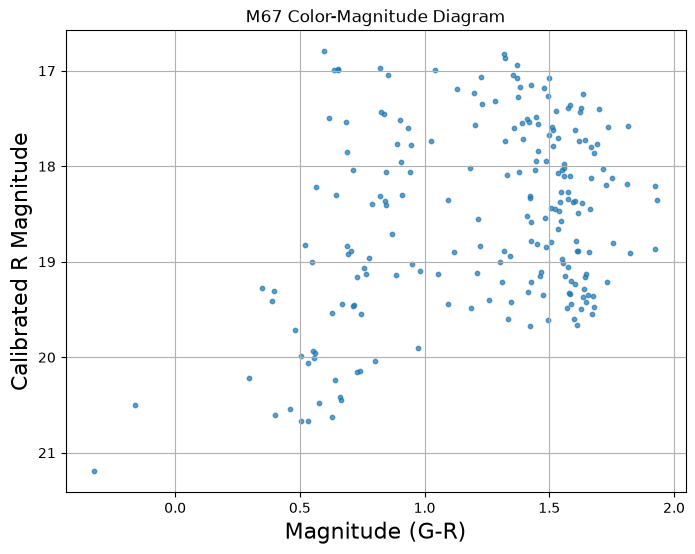

In [50]:
#Plot M67 Color-Magnitude Diagram

plt.figure(figsize=(8, 6))

plt.scatter((M67calibrated_Gmag - M67calibrated_Rmag)[valid_R],M67calibrated_Rmag[valid_R],s=10,alpha=0.7)

plt.gca().invert_yaxis()

#x-axis
plt.xlabel('Magnitude (G-R)',fontsize=16)

#y-axis
plt.ylabel('Calibrated R Magnitude',fontsize=16)

#title
plt.title('M67 Color-Magnitude Diagram')

plt.grid(True)
plt.show()

**Why:** We created a preliminary CMD to explore the distribution of stellar colors and magnitudes before using our aperture photometry measurements.

**What we found:** The diagram shows a diagonal distribution and some scattered sources. This first result helped us identify possible problems and improve the photometry.

In [51]:
# Check unusually blue sources in M67

M67color = M67calibrated_Gmag - M67calibrated_Rmag

blue_flag = M67color < -0.5

print("Total matched stars:", len(M67color))
print("Stars with G-R < -0.5:", np.sum(blue_flag))

print("G magnitudes of blue sources:")
print(M67calibrated_Gmag[blue_flag])

print("R magnitudes of blue sources:")
print(M67calibrated_Rmag[blue_flag])

Total matched stars: 368
Stars with G-R < -0.5: 20
G magnitudes of blue sources:
       mag        
------------------
15.395370264723471
15.650338348151601
15.049052468977655
15.238035407543517
 16.38882712110544
15.620866037133162
15.113403748509826
14.755767495811774
14.963270794797317
14.718149299130694
15.516201447292385
15.493887005679952
14.672751533831725
 15.41937324576405
15.820611920375384
15.179364483652117
14.729132008318423
15.241055246335671
15.479103746837335
 15.76056126739155
R magnitudes of blue sources:
       mag        
------------------
16.694552361565123
17.302221139416684
16.694550832919774
16.644038981152036
17.215269174265046
16.549558248215753
16.505232906696968
16.505234567668822
16.548583965835796
16.575682605753933
17.099740090338027
16.921505320293207
 16.69455279057243
 16.92400189902025
17.260144441662366
 16.50523418659775
16.595772109654778
 16.64403958364238
16.595771209197597
16.924000211672496


In [44]:
# Check positions of unusually blue stars in M67

M67blue_G = M67sources_G[matchflag][blue_flag]
M67blue_R = M67sources_R[idx[matchflag]][blue_flag]

print("Blue stars in G-band:")
print(M67blue_G['x_centroid', 'y_centroid', 'flux', 'peak'])

print("Blue stars in R-band:")
print(M67blue_R['x_centroid', 'y_centroid', 'flux', 'peak'])

Blue stars in G-band:
    x_centroid         y_centroid            flux           peak  
------------------ ------------------ ------------------ ---------
 2062.100948575844  368.7320708473089  694.7873363494873 38.634533
3292.4160080743104 395.56319322557863   549.369647026062 28.796787
3582.9177813535657   794.975836927526   955.826379776001  62.27865
2398.5275542060426 1319.9367545087666  803.1299781799316 47.880253
3598.4151306824515 1437.2310812213832  278.2717707157135 17.328735
 3409.663661227093 1590.1676265010592  564.4865326881409 32.835953
3228.9281756928194 1963.6338717023991  900.8209972381592 48.858105
2362.1079959664257  2172.866300497752 1252.2556552886963  70.49916
 728.0690104255864 2204.9255100045107 1034.4075508117676 56.090553
42.709860582895885 2207.1290146988654 1296.4037551879883  59.17891
1070.6469335973125 2441.0913522280202  621.6120448112488  30.86787
1886.3247646208172   2494.59395076802  634.5198278427124 33.771553
3021.1206291118756 2494.6985193498517 13

In [52]:
# Check catalog matching for M67

print("Matched stars:", np.sum(matchflag))
print("Unique R matches:", len(np.unique(idx[matchflag])))

print("Minimum separation (arcsec):",np.min(d2d[matchflag].arcsec))

print("Maximum separation (arcsec):",np.max(d2d[matchflag].arcsec))

print("Median separation (arcsec):",np.median(d2d[matchflag].arcsec))


Matched stars: 368
Unique R matches: 368
Minimum separation (arcsec): 0.001291020081127788
Maximum separation (arcsec): 0.3853032013018521
Median separation (arcsec): 0.023232681501937198


## M67 - Aperture Photometry
We will measure the flux of the stars using circular apertures
and subtract the local sky background.

In [53]:
# Read the original G and R images

from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

M67data_G, M67header_G=fits.getdata("M67 G-band image.fits", header=True)
M67data_R, M67header_R=fits.getdata("M67 R-band image.fits", header=True)

print("G-band shape:", M67data_G.shape)
print("R-band shape:", M67data_R.shape)

print("G-band units:", M67header_G.get("BUNIT"))
print("R-band units:", M67header_R.get("BUNIT"))

G-band shape: (3600, 3600)
R-band shape: (3600, 3600)
G-band units: nanomaggy
R-band units: nanomaggy


In [54]:
# Read the original G and R images

from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

M67data_G, M67header_G=fits.getdata("M67 G-band image.fits", header=True)
M67data_R, M67header_R=fits.getdata("M67 R-band image.fits", header=True)

print("G-band shape:", M67data_G.shape)
print("R-band shape:", M67data_R.shape)

print("G-band units:", M67header_G.get("BUNIT"))
print("R-band units:", M67header_R.get("BUNIT"))

G-band shape: (3600, 3600)
R-band shape: (3600, 3600)
G-band units: nanomaggy
R-band units: nanomaggy


In [55]:
from photutils.aperture import CircularAperture, CircularAnnulus

#aperture radii based on FWHM
r_G= 5.10
r_R= 4.59

# sky annulus radii
r_in_G=2*r_G
r_out_G=2.5*r_G
r_in_R = 2 * r_R
r_out_R =2.5 *r_R

In [56]:
from photutils.aperture import aperture_photometry

# positions of matched stars in G and R
positions_G = np.transpose((M67sources_G['x_centroid'][matchflag],M67sources_G['y_centroid'][matchflag]))

positions_R = np.transpose((M67sources_R['x_centroid'][idx[matchflag]],M67sources_R['y_centroid'][idx[matchflag]]))

# create circular apertures
aperture_G = CircularAperture(positions_G, r=r_G)
aperture_R = CircularAperture(positions_R, r=r_R)

#create sky annuli
annulus_G =CircularAnnulus(positions_G, r_in=r_in_G, r_out=r_out_G)
annulus_R =CircularAnnulus(positions_R, r_in=r_in_R, r_out=r_out_R)

#measure flux inside each aperture
phot_G =aperture_photometry(M67data_G, aperture_G)
phot_R =aperture_photometry(M67data_R, aperture_R)

#measure flux inside each sky annulus
sky_G = aperture_photometry(M67data_G, annulus_G)
sky_R = aperture_photometry(M67data_R, annulus_R)

print("Number of stars measured:", len(phot_G))
print("G-band aperture fluxes:")
print(phot_G['aperture_sum'][:5])

Number of stars measured: 368
G-band aperture fluxes:
   aperture_sum   
------------------
25.853293111370235
26.095460684899738
 9.404466313658434
 270.5173515510534
 529.0755319433191


In [57]:
# calculate the average sky background per pixel
mean_sky_G= sky_G['aperture_sum']/annulus_G.area
mean_sky_R=sky_R['aperture_sum']/annulus_R.area

# subtract the sky background from the aperture flux
flux_G= phot_G['aperture_sum'] -mean_sky_G * aperture_G.area
flux_R= phot_R['aperture_sum'] -mean_sky_R*aperture_R.area

# convert to numpy arrays
flux_G=np.array(flux_G)
flux_R=np.array(flux_R)

# Check which stars have positive flux in both filters
valid_flux=(np.isfinite(flux_G) & np.isfinite(flux_R) & (flux_G > 0) &(flux_R > 0))

print("Total measured stars:",len(flux_G))
print("Stars with valid flux:",np.sum(valid_flux))

print("G-band corrected flux:",flux_G[:5])
print("R-band corrected flux:",flux_R[:5])

Total measured stars: 368
Stars with valid flux: 368
G-band corrected flux: [ 25.17292712  25.94578295   9.30178836 268.80599723 525.86928236]
R-band corrected flux: [ 48.5153236   34.3754614   19.69615163 592.8714227  708.46906295]


In [58]:
#calculate magnitudes from the measured flux

mag_G=22.5- 2.5* np.log10(flux_G[valid_flux])
mag_R=22.5-2.5*np.log10(flux_R[valid_flux])

# calculate the color of each star
color_GR =mag_G- mag_R

# print the first five stars
print("G magnitudes:", mag_G[:5])
print("R magnitudes:", mag_R[:5])
print("G-R colors:",color_GR[:5])

print("Number of stars:",len(color_GR))

G magnitudes: [18.9976657  18.96483305 20.07858387 16.42640262 15.69780549]
R magnitudes: [18.28530267 18.65937866 19.26404655 15.56759871 15.37419777]
G-R colors: [0.71236304 0.30545439 0.81453731 0.85880391 0.32360772]
Number of stars: 368


In [59]:
# Estimate the sky noise in the G and R images
from astropy.stats import sigma_clipped_stats

mean_G, median_G, std_G = sigma_clipped_stats(M67data_G, sigma=3.0)

mean_R, median_R, std_R = sigma_clipped_stats(M67data_R, sigma=3.0)

# number of pixels in each aperture and sky annulus
N_ap_G= aperture_G.area
N_ap_R= aperture_R.area

N_sky_G= annulus_G.area
N_sky_R= annulus_R.area

# approximate flux uncertainties due to sky noise
sigma_flux_G=std_G*np.sqrt(N_ap_G+N_ap_G**2/N_sky_G)

sigma_flux_R=std_R*np.sqrt(N_ap_R+N_ap_R**2/N_sky_R)

print("G-band sky standard deviation:", std_G)
print("R-band sky standard deviation:", std_R)

print("G-band flux uncertainty:", sigma_flux_G)
print("R-band flux uncertainty:", sigma_flux_R)

G-band sky standard deviation: 0.0026621935
R-band sky standard deviation: 0.004611779
G-band flux uncertainty: 0.028922454859237494
R-band flux uncertainty: 0.045092730207846994


In [60]:
#convert flux uncertainties into magnitude uncertainties
sigma_mag_G = 1.086 * sigma_flux_G / flux_G[valid_flux]
sigma_mag_R = 1.086 * sigma_flux_R / flux_R[valid_flux]

# calculate color uncertainty
sigma_color = np.sqrt(sigma_mag_G**2+sigma_mag_R**2)

print("Mean G magnitude uncertainty:", np.mean(sigma_mag_G))
print("Mean R magnitude uncertainty:", np.mean(sigma_mag_R))

print("Mean color uncertainty:", np.mean(sigma_color))
print("First five color uncertainties:", sigma_color[:5])

Mean G magnitude uncertainty: 0.001399306566625812
Mean R magnitude uncertainty: 0.000966991640747787
Mean color uncertainty: 0.001744115608863681
First five color uncertainties: [1.60491970e-03 1.86948468e-03 4.19334583e-03 1.43095705e-04
 9.13532582e-05]


### M67 Color-Magnitude Diagram

We use the measured G and R magnitudes to make a
color-magnitude diagram. The color (G-R) is on the
horizontal axis and the G magnitude is on the vertical
axis. Brighter stars are shown at the top.

The uncertainties shown are preliminary estimates
based on sky background noise.

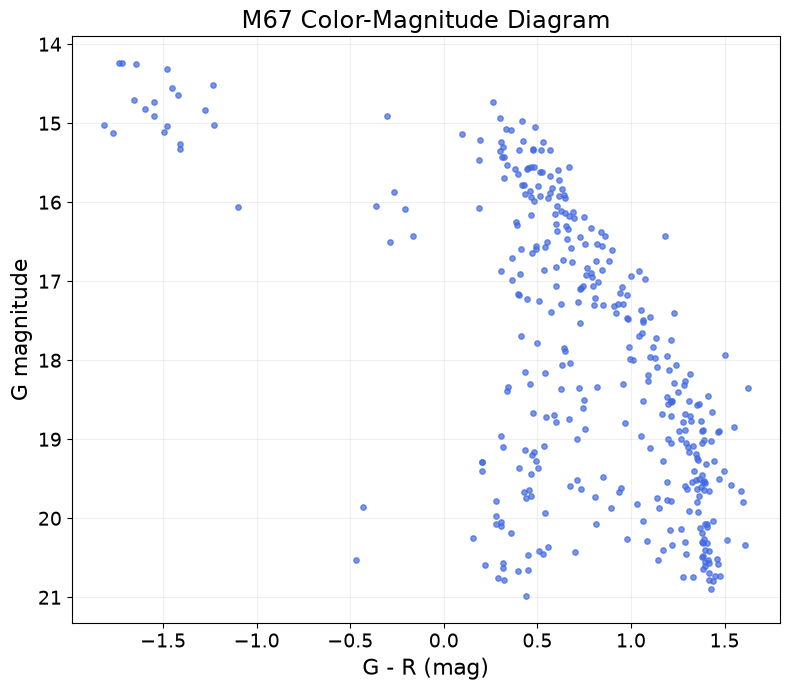

In [61]:
# M67 Color-Magnitude Diagram

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))

plt.scatter(color_GR,mag_G,s=15,color="royalblue",alpha=0.7)

plt.xlabel("G - R (mag)", fontsize=16)
plt.ylabel("G magnitude", fontsize=16)
plt.title("M67 Color-Magnitude Diagram", fontsize=17)

# Brighter stars appear at the top
plt.gca().invert_yaxis()

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Why:** We created this CMD using the fluxes measured with circular apertures after subtracting the sky background. This gives us a better estimate of the stellar magnitudes than the preliminary source detection values.

**What we found:** The CMD shows a diagonal group of stars, which is consistent with a possible main sequence. Some sources are scattered away from this group and may be affected by measurement errors or field star contamination.

In [62]:
# Check stars with unusually blue colors

blue_stars = color_GR < -0.5

print("Total stars:", len(color_GR))
print("Unusually blue stars:", np.sum(blue_stars))

print("Their G-R colors:")
print(color_GR[blue_stars])

Total stars: 368
Unusually blue stars: 20
Their G-R colors:
[-1.54876642 -1.76928783 -1.45432268 -1.59659831 -1.10093568 -1.27810936
 -1.42258601 -1.48090939 -1.23332962 -1.64339894 -1.49557237 -1.48115044
 -1.720332   -1.8165818  -1.41054024 -1.65348716 -1.73804197 -1.54881973
 -1.22550793 -1.41144745]


Original number of stars: 368
Stars excluded: 20
Stars remaining: 348


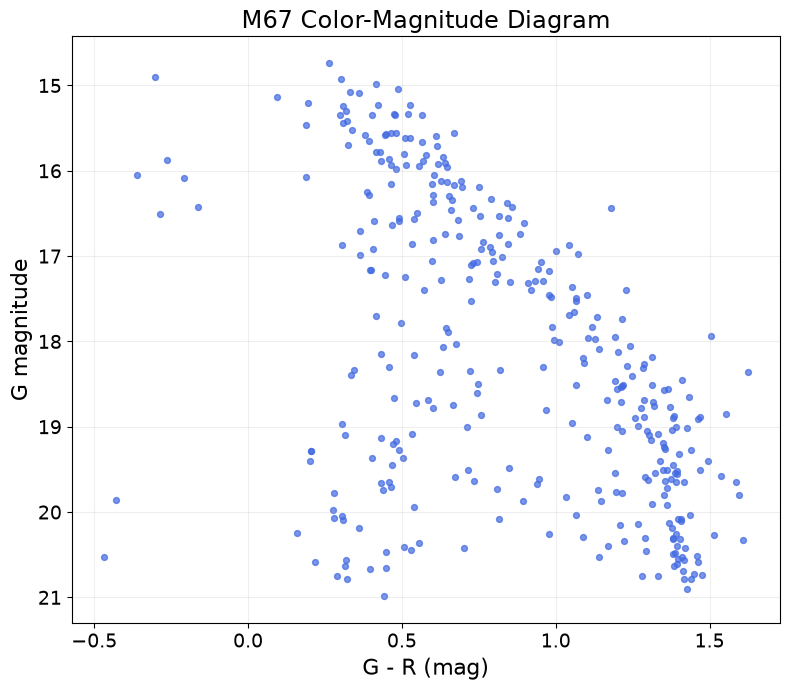

In [63]:
# remove extremely blue sources for a preliminary CMD
good_stars =color_GR >=-0.5

print("Original number of stars:",len(color_GR))
print("Stars excluded:",np.sum(~good_stars))
print("Stars remaining:",np.sum(good_stars))

plt.figure(figsize=(8, 7))

plt.scatter(color_GR[good_stars],mag_G[good_stars],s=18,color="royalblue",alpha=0.7)

plt.xlabel("G - R (mag)", fontsize=16)
plt.ylabel("G magnitude", fontsize=16)
plt.title("M67 Color-Magnitude Diagram", fontsize=17)

plt.gca().invert_yaxis()

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Why:** We removed sources with extremely blue colors to check whether they were affecting the distribution of stars in the CMD.

**What we found:** We removed 20 sources and kept 348. The main diagonal structure remained visible. However, the color limit is only an exploratory quality check and does not prove that the excluded sources are incorrect.

### M67 Results and Discussion

We matched 368 sources between the G and R images of M67. We measured their fluxes using circular apertures and subtracted the sky background. We then calculated the G and R magnitudes and the G-R colors.

We found 20 sources with very negative colors (G-R less than -0.5). We excluded these sources from a second CMD to make the main sequence easier to see. This leaves 348 sources in the diagram.

The CMD shows a visible main sequence. Brighter stars are generally bluer, while fainter stars are redder. However, there is some scatter around the sequence.

Some of this scatter may come from field stars, overlapping sources, or photometric errors. The main-sequence turnoff and red giant branch are not clear enough to measure reliably from this diagram.

Our photometric uncertainties are preliminary because they only include an estimate of the sky background noise. A more complete uncertainty calculation would also include other sources of noise and possible correlations between pixels.

Original matched sources: 368
Good positional matches: 344
Sources without suspicious R peaks: 346
Final selected sources: 338
Excluded sources: 30


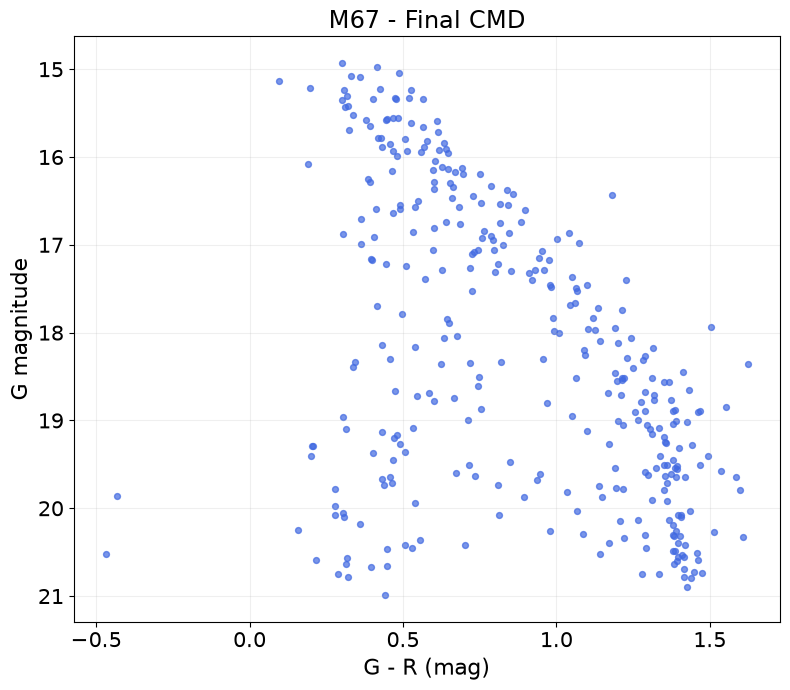

In [64]:

# M67 - Final source selection

#check matching distance
good_match_M67 =d2d[matchflag].arcsec < 0.1

#exclude sources with suspicious R-band peaks
good_peak_M67 =~suspect_R

#combine the quality checks
good_M67=good_match_M67 & good_peak_M67 & valid_flux

print("Original matched sources:",len(good_M67))
print("Good positional matches:",np.sum(good_match_M67))
print("Sources without suspicious R peaks:",np.sum(good_peak_M67))
print("Final selected sources:",np.sum(good_M67))
print("Excluded sources:",np.sum(~good_M67))

#final M67 CMD
plt.figure(figsize=(8, 7))

plt.scatter(color_GR[good_M67],mag_G[good_M67],s=18,color="royalblue",alpha=0.7)

plt.xlabel("G - R (mag)",fontsize=16)
plt.ylabel("G magnitude",fontsize=16)
plt.title("M67 - Final CMD",fontsize=17)

plt.gca().invert_yaxis()

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


**Why:** We applied stricter matching and source quality criteria to create our final CMD with more reliable measurements.

**What we found:** We selected 338 sources from the original 368 matches. The CMD still shows a clear diagonal structure, consistent with a possible main sequence. The mean G-R color is 0.872 magnitudes, and the G magnitudes range from 14.929 to 20.987.

The main structure remained visible after the quality checks, although some sources may still be field stars or have uncertain photometry.

In [65]:

#M67 - Final results

print("Final sources:", np.sum(good_M67))
print("Mean G-R:",np.mean(color_GR[good_M67]))
print("Median G-R:",np.median(color_GR[good_M67]))
print("Brightest G:",np.min(mag_G[good_M67]))
print("Faintest G:",np.max(mag_G[good_M67]))
print("Mean color uncertainty:",np.mean(sigma_color[good_M67]))


Final sources: 338
Mean G-R: 0.8716386894820742
Median G-R: 0.8176915393035227
Brightest G: 14.928644762751514
Faintest G: 20.987325467269482
Mean color uncertainty: 0.0018840545558185945


### M67 Results and Conclusion

M67 is an open cluster. In this analysis, we used G and R images to study its stellar population.

We initially detected 522 sources in the G-band and 777 sources in the R-band. We measured the FWHM of the stars, obtaining 5.10 pixels in G and 4.59 pixels in R. These values helped us choose the sizes of our circular apertures.

We matched 368 sources between the two filters to measure the same stars in both images. We then used aperture photometry and subtracted the local sky background to obtain more accurate stellar fluxes. After converting the fluxes into magnitudes, we calculated the G-R colors.

After applying our quality checks, we selected 338 sources for the final color-magnitude diagram (CMD).

The final sample has a mean G-R color of 0.872 magnitudes and a median color of 0.818 magnitudes. The G magnitudes range from 14.929 to 20.987. The mean estimated color uncertainty is 0.00188 magnitudes.

The CMD shows a diagonal group of stars, which is consistent with a possible main sequence. Some stars are scattered away from this group. These may be field stars or sources affected by photometric errors.

The quality checks helped remove 30 sources, but they cannot guarantee that all the remaining sources belong to M67.

Our analysis also has some limitations. Nearby stars may affect the aperture photometry and the sky background measurements. In addition, the calculated uncertainties mainly consider sky background noise, so the true errors may be larger.

Overall, we successfully detected stars, measured stellar fluxes, calculated magnitudes and colors, and created a CMD for M67. This helped us understand how photometry can be used to study stellar populations. The results can now be compared with those of the globular cluster M5.